<a href="https://colab.research.google.com/github/santana-robledo/Posgrado_Robotica_e_Inteligencia_Artificial/blob/main/Vision_Artificial/08.%20SegmentacionChallenge.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Importamos líbrerías
import numpy as np
import matplotlib.pyplot as plt
import cv2

# Lectura de la imagen

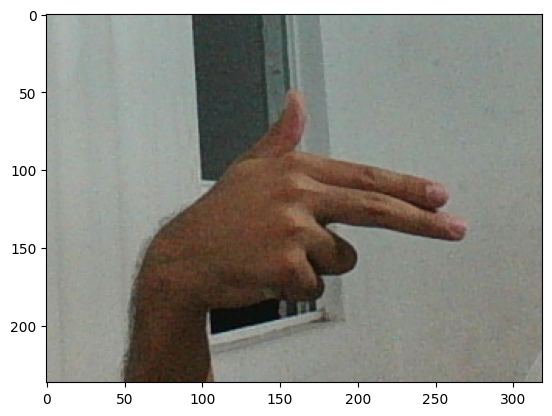

In [ ]:
# Lectura de la imagen mediante opencv
imagen = cv2.imread('718.png')
imagenRGB = cv2.cvtColor(imagen, cv2.COLOR_BGR2RGB)
plt.imshow(imagenRGB)
plt.show()

## Escala de grises

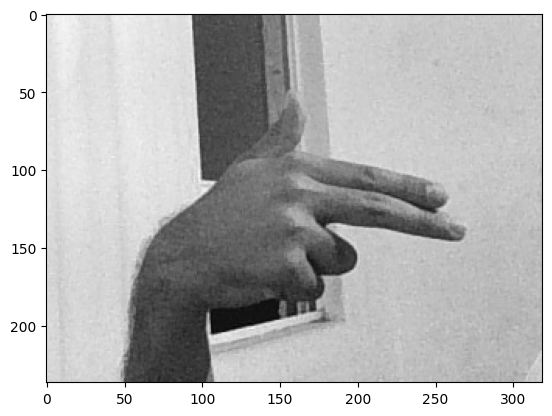

In [ ]:
imagenGray = cv2.cvtColor(imagen, cv2.COLOR_BGR2GRAY)

plt.imshow(imagenGray, cmap='gray')
plt.show()

## Filtro sobre la imagen

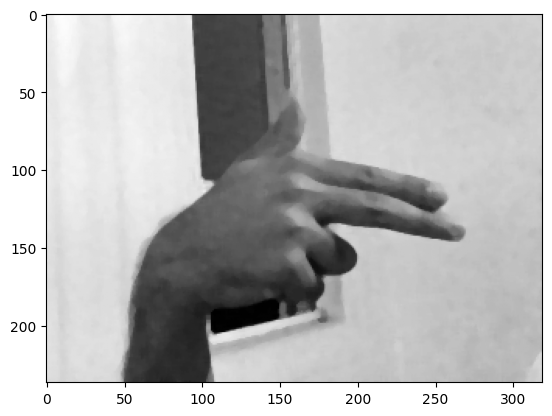

In [ ]:
imagenFiltrada = cv2.medianBlur(imagenGray, 5)
plt.imshow(imagenFiltrada, cmap='gray')
plt.show()

# Segmentación de la mano

## Binarizado de la imagen

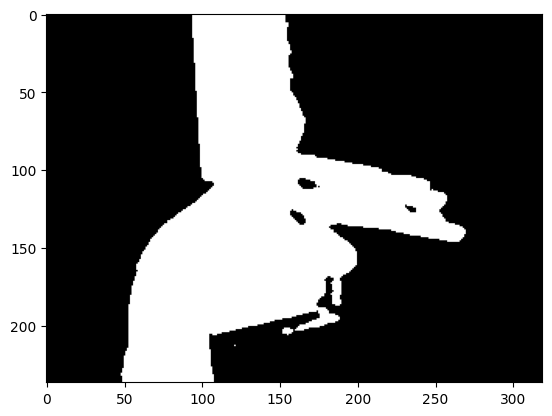

In [ ]:
# Binarizado por medio de un límite
ret, imagenBinL = cv2.threshold(imagenFiltrada, thresh = 120, maxval = 255, type = cv2.THRESH_BINARY_INV)

plt.imshow(imagenBinL, cmap='gray')
plt.show()

## Segmentación por color

In [ ]:
# Define el rango de color para la mano
print(imagenRGB[200, 75])
print(imagenRGB[150, 100])
print(imagenRGB[125, 125])
print(imagenRGB[100, 150])
print(imagenRGB[125, 200])

[72 50 36]
[85 54 34]
[105  77  56]
[107  72  50]
[90 63 44]


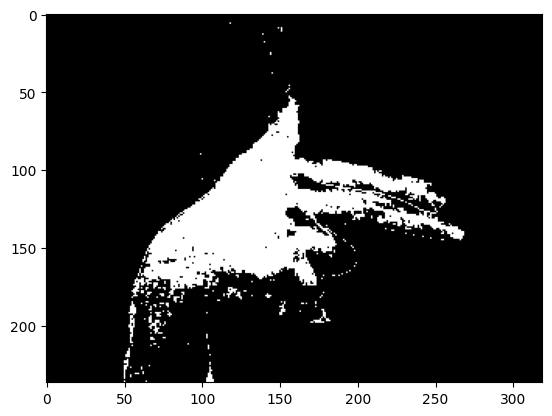

In [ ]:
imagenBinC = np.zeros((imagen.shape[0], imagen.shape[1]))

for i in range(imagen.shape[0]):
  for j in range(imagen.shape[1]):
      if (72 <= imagenRGB[i,j,0] <= 137) and \
       (50 <= imagenRGB[i,j,1] <= 107) and \
       (24 <= imagenRGB[i,j,2] <= 80):
       imagenBinC[i,j] = 255

plt.imshow(imagenBinC, cmap = 'gray')
plt.show()

## Segmentación con HSV

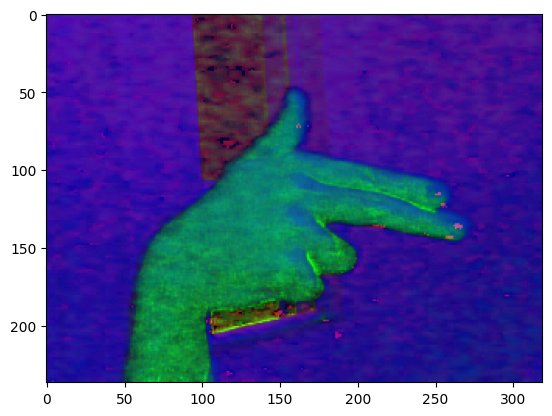

In [ ]:
imagenHSV = cv2.cvtColor(imagen, cv2.COLOR_BGR2HSV)
plt.imshow(imagenHSV, cmap = 'hsv')
plt.show()

In [ ]:
# Define el rango de color para la mano
print(imagenHSV[200, 75])
print(imagenHSV[150, 100])
print(imagenHSV[125, 125])
print(imagenHSV[100, 150])
print(imagenHSV[125, 200])

[ 12 128  72]
[ 12 153  85]
[ 13 119 105]
[ 12 136 107]
[ 12 130  90]


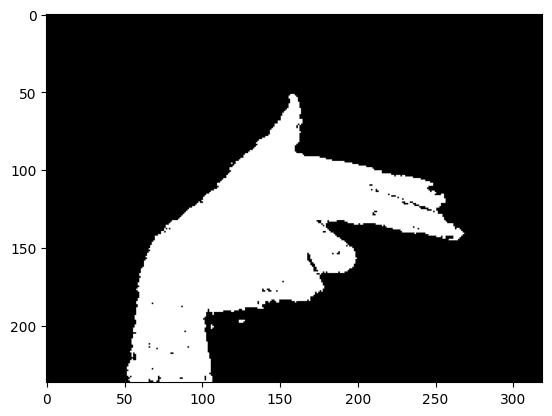

In [ ]:
imagenBinD = np.zeros((imagen.shape[0], imagen.shape[1]))

for i in range(imagen.shape[0]):
  for j in range(imagen.shape[1]):
      if (0 <= imagenHSV[i,j,0] <= 30) and \
       (80 <= imagenHSV[i,j,1] <= 183) and \
       (12 <= imagenHSV[i,j,2] <= 200):
       imagenBinD[i,j] = 255

plt.imshow(imagenBinD, cmap = 'gray')
plt.show()

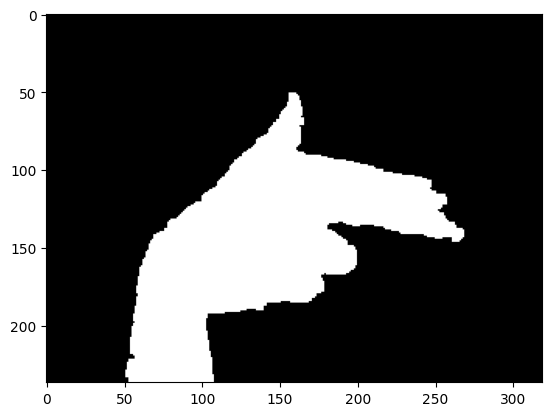

In [ ]:
# Erosión y dilatación
kernel = np.ones((3,3))
imagenEro = cv2.erode(imagenBinD, kernel, iterations = 1)
imagenDil = cv2.dilate(imagenEro, kernel, iterations = 2)

plt.imshow(imagenDil, cmap = 'gray')
plt.show()